In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

PI = np.pi

## calcualte the probability of detection |1>
def ideal_rabi_t(t, detune, omega):
  omg = (omega**2 + detune**2)
  term = np.sin(np.sqrt(omg)/2*t)
  return omega**2/omg*term*term

# Population vs. detuning

0.6283185307179586
Optimized parameters (a, b, c): [5.         0.62831853]


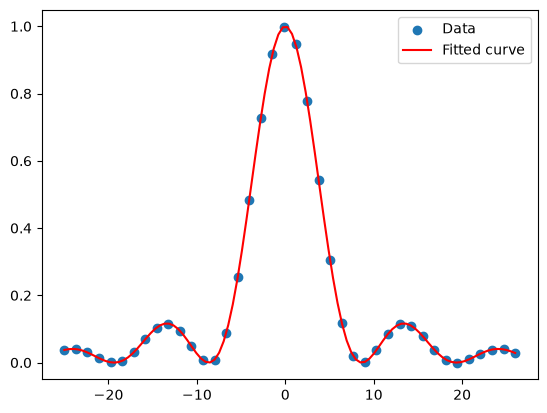

In [ ]:
omega = 5 # MHz
t = PI/omega
initial_guesses = [4, 0.5]
print("t" = t)

# 1. detuning as the independent variable
def model_func(x, omega, t):
  omg = (omega**2 + x**2)
  term = np.sin(np.sqrt(omg)/2*t)
  return omega**2/omg*term*term

# 2. Prepare your data
x_data = np.linspace(-5 * omega, 5 * omega +1, 40)
# x_data = np.arange(-5 * omega, 5 * omega+1, 2*5*omega/100)
y_data = model_func(x_data, omega, t)

# 3. Fit the curve (p0 provides initial guesses for parameters a, b, c)
popt, pcov = curve_fit(model_func, x_data, y_data, p0=initial_guesses)

# popt contains the optimal parameter values
print("Optimized parameters (a, b, c):", popt)

# 4. Generate smooth x values to plot the fitted curve
x_fit = np.linspace(min(x_data), max(x_data), 100)
y_fit = model_func(x_fit, *popt)

# 5. Plot original data and the fitted curve
plt.scatter(x_data, y_data, label="Data")
plt.plot(x_fit, y_fit, color="red", label="Fitted curve")
plt.legend()
plt.show()

# Population vs. rabi flopping time

Optimized parameters (a, b, c): [ 9.99999999e-01 -4.07513446e-05]


C:\Users\Lana\AppData\Local\Temp\ipykernel_4372\2399884569.py:19: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(model_func, x_data, y_data, p0=initial_guesses)


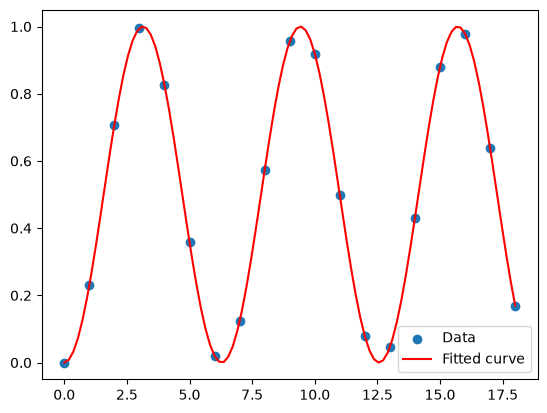

In [ ]:
from scipy.optimize import curve_fit

omega = 1 # MHz
detune = 0
initial_guesses = [1.1, 0.1]

# 1. detuning as the independent variable
def model_func(x, omega, detune):
  omg = (omega**2 + detune**2)
  term = np.sin(np.sqrt(omg)/2*x)
  return omega**2/omg*term*term

# 2. Prepare your data
x_data = np.arange(0, 6*np.pi/omega, 1)
y_data = model_func(x_data, omega, detune)

# 3. Fit the curve (p0 provides initial guesses for parameters a, b, c)
popt, pcov = curve_fit(model_func, x_data, y_data, p0=initial_guesses)

# popt contains the optimal parameter values
print("Optimized parameters (a, b, c):", popt)

# 4. Generate smooth x values to plot the fitted curve
x_fit = np.linspace(min(x_data), max(x_data), 100)
y_fit = model_func(x_fit, *popt)

# 5. Plot original data and the fitted curve
plt.scatter(x_data, y_data, label="Data")
plt.plot(x_fit, y_fit, color="red", label="Fitted curve")
plt.legend()
plt.show()

# Overlay theory and experiment

650 theory values
our_ba138_freq650 (lab value) 461.311725 THz
	 theory_ba137_freq650_D3P2 461.31183175 THz
	 theory_ba137_freq650_D2P1 461.310958075 THz
	 theory_ba137_freq650_D1P1 461.311292995 THz
	 theory_ba137_freq650_D0P1 461.311438185 THz
650 lab values
	 lab_ba138_freq650_central = D3P2 461.31182 THz
	 ba138_EOM650 -94.99999998752173 MHz
	 expr_ba137_freq650_D3P2 461.31182 THz
	 expr_ba137_freq650_D2P1 461.31093500000003 THz
	 expr_ba137_freq650_D1P1 461.31129500000003 THz
	 expr_ba137_freq650_D0P1 461.311438 THz


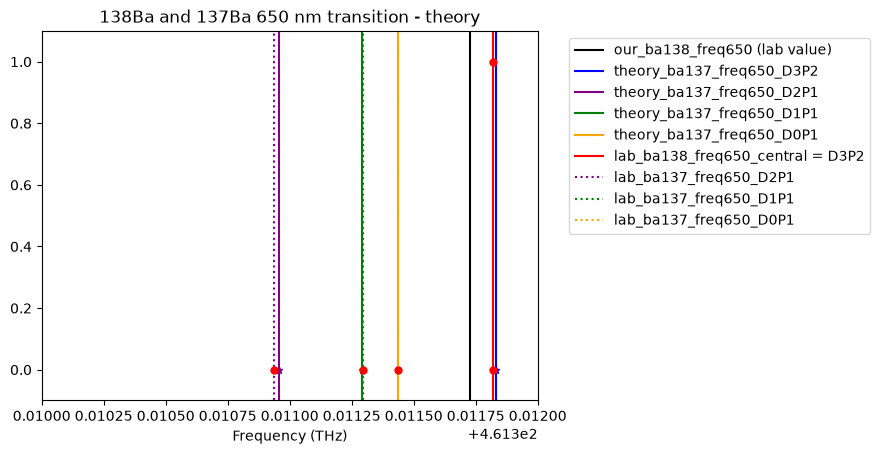

In [10]:
plt.plot()
plot_650_theory(our_ba138_freq650, "our_ba138_freq650 (lab value)")
plot_650_lab(lab_ba138_freq650_central, "lab_ba138_freq650_central = D3P2",
            ba137_EOM650_D0P1 = ba137_EOM650_D0P1,
            ba137_EOM650_D1P1 = ba137_EOM650_D1P1,
            ba137_EOM650_D2P1 = ba137_EOM650_D2P1,
            our_ba138_freq650 = our_ba138_freq650,
            plot_not_used=False)
plt.xlim(461.310, 461.312)
plt.ylim(-0.1, 1.1)
plt.xlabel("Frequency (THz)")
plt.title ("138Ba and 137Ba 650 nm transition - theory")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()